# 02. GRU or LSTM, and how large?

**Question:** which recurrent architecture should the final model use?

**Already known from the EDA:** word BiLSTM led word BiGRU by 0.018 on one seed. Its interval only covers the saved models, not retraining, so that lead is unconfirmed. Nothing else has been tried: only one layer, 96 units, no CRF.

GRU and LSTM get three seeds on the same rows, so the comparison includes training noise. Other options get one seed first, then the top ones are repeated.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "eda").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "model")]

import pandas as pd
from IPython.display import display

from nerkit import plots
from nerkit.config import SEEDS
from nerkit.experiment import confirm, read_results, records_named, run_grid, summarize, top_names

NOTEBOOK = "02_architecture"

## 1. GRU vs LSTM, three seeds
Same seeds, same data. If the mean difference is smaller than the range of per-seed differences, call it a tie and take the cheaper GRU.

gru: F1 mix 0.839, uk 0.829, ru 0.907, 180 s on cpu
gru: F1 mix 0.837, uk 0.827, ru 0.913, 173 s on cpu
gru: F1 mix 0.832, uk 0.821, ru 0.907, 144 s on cpu
lstm: F1 mix 0.837, uk 0.826, ru 0.913, 198 s on cpu
lstm: F1 mix 0.841, uk 0.831, ru 0.908, 171 s on cpu
lstm: F1 mix 0.841, uk 0.830, ru 0.913, 204 s on cpu


name,gru,lstm,lstm_minus_gru
seed,,,
3012026,0.839,0.837,-0.002
3012027,0.837,0.841,0.004
3012028,0.832,0.841,0.008


Mean LSTM - GRU: +0.003; range -0.002 to +0.008


,parameters,minutes
name,,
gru,234483.0,2.76
lstm,312435.0,3.18


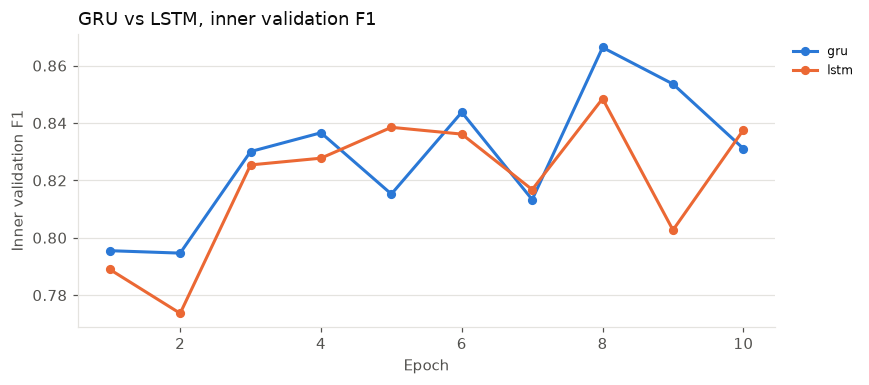

In [2]:
run_grid(NOTEBOOK, {"gru": dict(rnn="gru"), "lstm": dict(rnn="lstm")}, seeds=SEEDS)
table = read_results(NOTEBOOK)
table = table[table.name.isin(["gru", "lstm"]) & (table.fold == 0)]
paired = table.pivot(index="seed", columns="name", values="mix_f1")
paired["lstm_minus_gru"] = paired["lstm"] - paired["gru"]
display(paired.round(3))
print(f"Mean LSTM - GRU: {paired.lstm_minus_gru.mean():+.3f}; range {paired.lstm_minus_gru.min():+.3f} to {paired.lstm_minus_gru.max():+.3f}")
display(table.groupby("name")[["parameters", "minutes"]].mean().round(2))
plots.learning_curves(records_named(NOTEBOOK, ["gru", "lstm"]), title="GRU vs LSTM, inner validation F1");

## 2. Direction, depth, width and CRF
The unidirectional run is a reference for the report: the tagger should lose context from the right. Set `RNN` to the winner of section 1.

Using GRU for the rest of this notebook
unidirectional: F1 mix 0.798, uk 0.786, ru 0.888, 108 s on cpu
layers_2: F1 mix 0.838, uk 0.827, ru 0.918, 283 s on cpu
layers_3: F1 mix 0.839, uk 0.827, ru 0.919, 246 s on cpu
hidden_192: F1 mix 0.843, uk 0.834, ru 0.907, 134 s on cpu
hidden_384: F1 mix 0.841, uk 0.831, ru 0.914, 225 s on cpu
layers_2_hidden_192: F1 mix 0.839, uk 0.828, ru 0.913, 235 s on cpu
crf: F1 mix 0.856, uk 0.846, ru 0.924, 115 s on cpu
layers_2_hidden_192_crf: F1 mix 0.852, uk 0.844, ru 0.904, 179 s on cpu


,runs,vs_baseline,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,,
crf,1,0.020,0.856,0.000,0.846,0.924,0.848,0.864,0.669,0.832,0.617,1.924
layers_2_hidden_192_crf,1,0.016,0.852,0.000,0.844,0.904,0.848,0.855,0.689,0.838,0.684,2.979
hidden_192,1,0.007,0.843,0.000,0.834,0.907,0.842,0.844,0.632,0.821,0.575,2.234
hidden_384,1,0.005,0.841,0.000,0.831,0.914,0.856,0.827,0.616,0.819,0.560,3.747
lstm,3,0.003,0.839,0.004,0.829,0.911,0.820,0.860,0.662,0.836,0.604,3.183
layers_2_hidden_192,1,0.003,0.839,0.000,0.828,0.913,0.842,0.836,0.609,0.825,0.537,3.921
layers_3,1,0.002,0.839,0.000,0.827,0.919,0.828,0.849,0.624,0.845,0.518,4.102
layers_2,1,0.002,0.838,0.000,0.827,0.918,0.817,0.861,0.685,0.820,0.621,4.725
gru,3,0.000,0.836,0.007,0.826,0.909,0.818,0.856,0.653,0.820,0.618,2.756


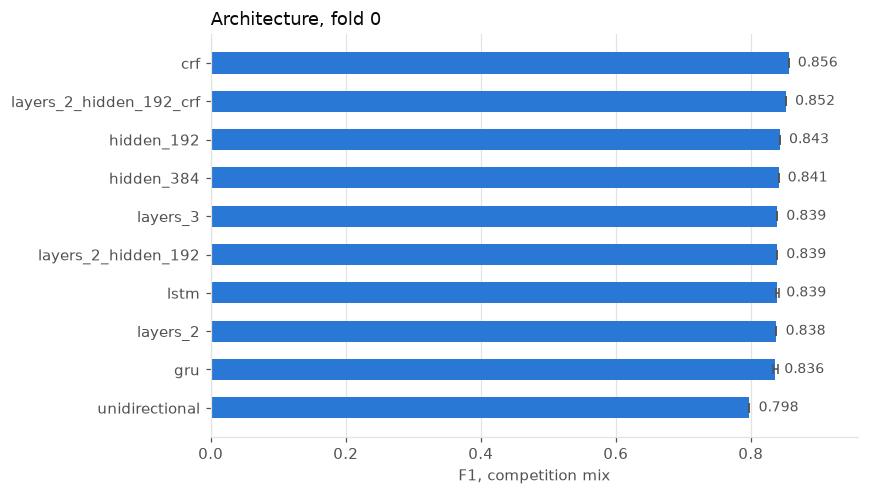

In [3]:
# LSTM only if it beats GRU on every seed; otherwise the cheaper GRU.
RNN = "lstm" if (paired["lstm"] > paired["gru"]).all() else "gru"
print("Using", RNN.upper(), "for the rest of this notebook")
EXPERIMENTS = {
    "unidirectional": dict(rnn=RNN, bidirectional=False),
    "layers_2": dict(rnn=RNN, layers=2),
    "layers_3": dict(rnn=RNN, layers=3),
    "hidden_192": dict(rnn=RNN, hidden=192),
    "hidden_384": dict(rnn=RNN, hidden=384),
    "layers_2_hidden_192": dict(rnn=RNN, layers=2, hidden=192),
    "crf": dict(rnn=RNN, crf=True),
    "layers_2_hidden_192_crf": dict(rnn=RNN, layers=2, hidden=192, crf=True),
}
run_grid(NOTEBOOK, EXPERIMENTS)
summary = summarize(NOTEBOOK, baseline=RNN)
display(summary)
plots.scores_chart(summary, "Architecture, fold 0");

## 3. Health checks
Gradients that fall towards zero in the earlier layers suggest vanishing gradients. Sudden spikes suggest instability. If validation loss rises while training loss falls, the model is overfitting. Rows are few at this stage, so overfitting here may shrink with more data (notebook 04).

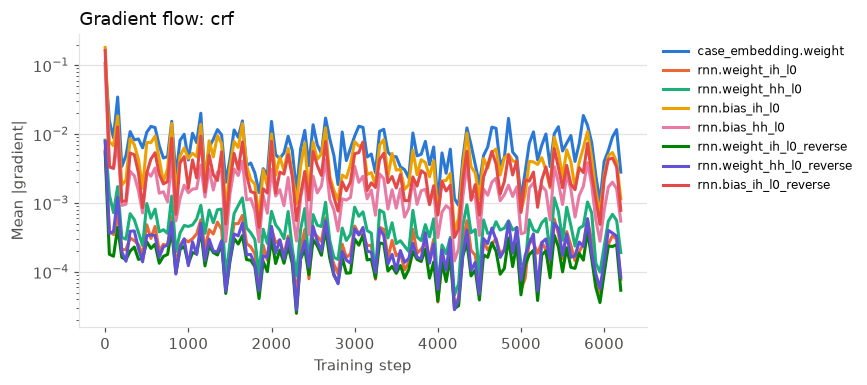

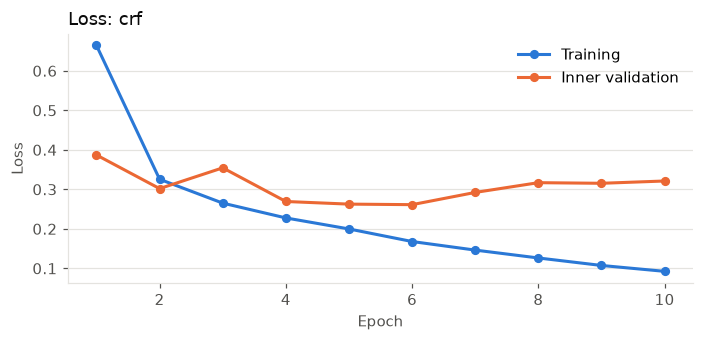

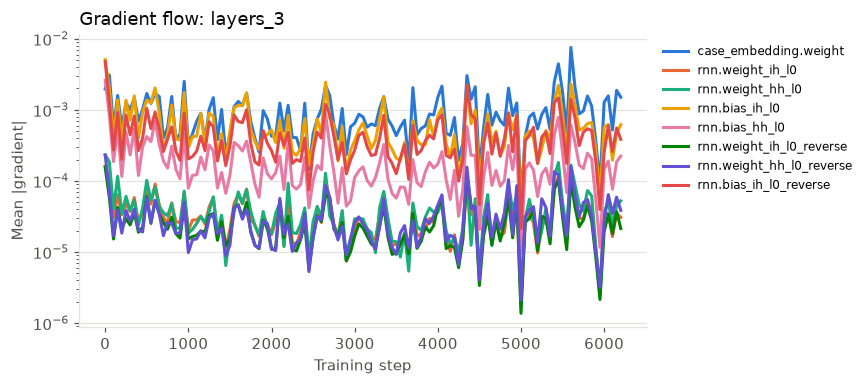

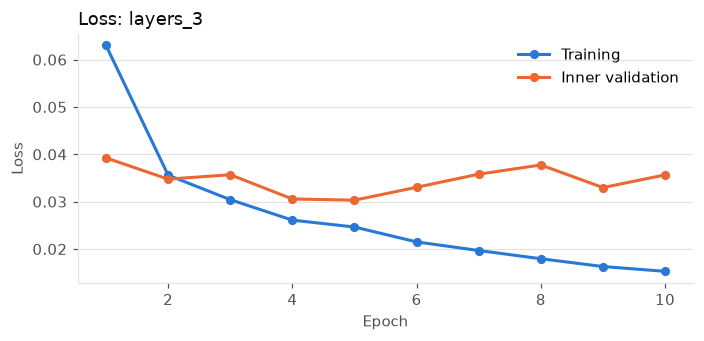

In [4]:
deepest = records_named(NOTEBOOK, ["layers_3"])
best_record = records_named(NOTEBOOK, top_names(NOTEBOOK, 1))
for record in best_record + deepest:
    plots.gradient_flow(record)
    plots.train_vs_validation(record)

## 4. Confirm on all folds
This is the cross-validation step: the top two configurations run on folds 1 and 2 with one seed, then pooled with fold 0. Choose by mean F1 mix.

In [5]:
finalists = top_names(NOTEBOOK, 2)
confirm(NOTEBOOK, finalists)
display(summarize(NOTEBOOK, fold=None).loc[finalists])

crf: F1 mix 0.863, uk 0.855, ru 0.914, 115 s on cpu
crf: F1 mix 0.870, uk 0.862, ru 0.921, 83 s on cpu
layers_2_hidden_192_crf: F1 mix 0.853, uk 0.847, ru 0.895, 134 s on cpu
layers_2_hidden_192_crf: F1 mix 0.869, uk 0.861, ru 0.923, 226 s on cpu


,runs,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,
crf,3,0.863,0.014,0.854,0.920,0.864,0.862,0.682,0.838,0.619,1.742
layers_2_hidden_192_crf,3,0.858,0.017,0.851,0.907,0.874,0.843,0.645,0.832,0.648,2.997


## 5. Paired check: the same GRU without a CRF on folds 1 and 2
The CRF gain was measured against a GRU only on fold 0. Folds differ by about 0.007 in difficulty (the CRF scored 0.856, 0.863 and 0.870 on folds 0, 1 and 2), so this runs the plain GRU on the other two folds, with the same seed, for a like-for-like comparison. About 6 minutes.

In [6]:
confirm(NOTEBOOK, ["gru"], folds=(1, 2))
table = read_results(NOTEBOOK)
table = table[table.name.isin(["gru", "crf"]) & (table.seed == SEEDS[0])]
paired_crf = table.pivot(index="fold", columns="name", values="mix_f1")
paired_crf["crf_minus_gru"] = paired_crf["crf"] - paired_crf["gru"]
display(paired_crf.round(3))
print(f"CRF gain over the GRU: mean {paired_crf.crf_minus_gru.mean():+.3f}, smallest {paired_crf.crf_minus_gru.min():+.3f}")

gru: F1 mix 0.833, uk 0.826, ru 0.876, 60 s on cpu
gru: F1 mix 0.847, uk 0.839, ru 0.903, 87 s on cpu


name,crf,gru,crf_minus_gru
fold,,,
0,0.856,0.839,0.017
1,0.863,0.833,0.030
2,0.870,0.847,0.023


CRF gain over the GRU: mean +0.023, smallest +0.017


## Results summary (fold 0, one seed unless noted)

Scores are F1 mix. Three seeds of the same setup varied by 0.004 to 0.007, so gaps under about 0.01 are ties.

| Option | F1 mix | Compared with GRU (0.836, 3 seeds) |
| --- | ---: | --- |
| GRU, 3 seeds | 0.836 | |
| LSTM, 3 seeds | 0.839 | +0.003, a tie |
| Unidirectional GRU | 0.798 | **-0.038** |
| 2 layers, 3 layers | 0.838, 0.839 | tie |
| 192 or 384 hidden units | 0.843, 0.841 | tie |
| 2 layers with 192 hidden units | 0.839 | tie |
| **CRF** | **0.856** | **+0.020** |
| CRF with 2 layers and 192 hidden units | 0.852 | +0.016, no better than the small CRF |

### What we learned

1. **GRU and LSTM tie.** LSTM led by +0.003 on average and won 2 of 3 seeds (range -0.002 to +0.008). The rule picked GRU, which has 25% fewer parameters (0.23M against 0.31M) and trains about 13% faster.
2. **Reading in both directions matters.** The unidirectional model lost 0.038, mostly in precision (0.749 against 0.818). Without the words to the right, it over-predicts.
3. **A bigger network doesn't help.** Two or three layers and 192 or 384 units all land at 0.838 to 0.843, inside the noise, at up to twice the training time. Unseen-name recall also stays at 0.61 to 0.69. Capacity isn't the limit: the frozen vectors and the amount of labeled data are, so more data (notebook 04) is the next lever.
4. **The CRF is the one clear gain.** It scored 0.856 against 0.839 for the GRU with the same seed (+0.017), and its precision and recall improved together. It was ahead of all 8 non-CRF variants. A CRF scores whole tag sequences, so it avoids broken spans such as an I tag with no B before it. The paired check in section 5 confirmed it on every fold. The CRF against the same GRU scored 0.856 against 0.839 on fold 0, 0.863 against 0.833 on fold 1 and 0.870 against 0.847 on fold 2: gains of +0.017, +0.030 and +0.023 (mean +0.023). A bigger CRF (2 layers, 192 units) scored 0.858 over 3 folds, so size doesn't add anything there either.
5. **The competition-style checks are noisy.** The 26-post F1 ranged from 0.518 to 0.684 across similar models and is not used for choosing.

### Trade-offs of the CRF

- It decodes with Viterbi, so the probability threshold from notebook 05 doesn't apply, and that was the way to test a recall-leaning setting for the leaderboard.
- It has no class weights, so those runs in notebook 03 are skipped.
- It saves transition scores with the logits. The saved logits still work for ensembling, but averaged ensembles decode without the CRF.

### Decisions for `nerkit/decisions.py`

```python
"rnn": "gru", "crf": True,  # 1 layer, 96 units, bidirectional stay at their defaults
```

These are applied in `decisions.py`.

### Caveats

- Every variant except GRU and LSTM has one seed. The CRF gain is confirmed on all three folds, with one seed per fold.
- Several runs reached the 10-epoch limit near their best epoch (best epochs ranged from 2 to 9), so a longer schedule might shift small differences. The scheduler and learning rate are tested in notebook 03.